In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [13]:
# Đường dẫn tới bộ dữ liệu
DATA_PATH = "../data/raw/UCI HAR Dataset"

print(DATA_PATH)

../data/raw/UCI HAR Dataset


In [14]:
print("Đường dẫn tồn tại:", os.path.exists(DATA_PATH))

Đường dẫn tồn tại: True


In [20]:
features = pd.read_csv(
    DATA_PATH + "/features.txt",
    sep=r"\s+",
    header=None,
    names=["Index", "Feature"]
)

features.head()

,Index,Feature
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y


In [19]:
feature_names = features["Feature"].tolist()

print("Số lượng đặc trưng:", len(feature_names))

Số lượng đặc trưng: 561


In [21]:
X_train = pd.read_csv(
    DATA_PATH + "/train/X_train.txt",
    sep=r"\s+",
    header=None
)

X_train.columns = feature_names

X_train.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [22]:
print(X_train.shape)

(7352, 561)


In [25]:
y_train = pd.read_csv(
    DATA_PATH + "/train/y_train.txt",
    header=None,
    names=["Activity"]
)

y_train.head()

,Activity
0,5
1,5
2,5
3,5
4,5


In [26]:
print(y_train.shape)

(7352, 1)


In [27]:
subject_train = pd.read_csv(
    DATA_PATH + "/train/subject_train.txt",
    header=None,
    names=["Subject"]
)

subject_train.head()

,Subject
0,1
1,1
2,1
3,1
4,1


In [29]:
print(subject_train.shape)

(7352, 1)


In [30]:
train_data = pd.concat(
    [subject_train, y_train, X_train],
    axis=1
)

train_data.head()

,Subject,Activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [31]:
print(train_data.shape)

(7352, 563)


### BƯỚC 4 - KHÁM PHÁ DỮ LIỆU

In [32]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 563 entries, Subject to angle(Z,gravityMean)
dtypes: float64(561), int64(2)
memory usage: 31.6 MB


In [33]:
train_data.describe()

,Subject,Activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
count,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,...,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000
mean,17.413085,3.643362,0.274488,-0.017695,-0.109141,-0.605438,-0.510938,-0.604754,-0.630512,-0.526907,...,0.125293,-0.307009,-0.625294,0.008684,0.002186,0.008726,-0.005981,-0.489547,0.058593,-0.056515
std,8.975143,1.744802,0.070261,0.040811,0.056635,0.448734,0.502645,0.418687,0.424073,0.485942,...,0.250994,0.321011,0.307584,0.336787,0.448306,0.608303,0.477975,0.511807,0.297480,0.279122
min,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-0.999873,-1.000000,-1.000000,-1.000000,...,-1.000000,-0.995357,-0.999765,-0.976580,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,8.000000,2.000000,0.262975,-0.024863,-0.120993,-0.992754,-0.978129,-0.980233,-0.993591,-0.978162,...,-0.023692,-0.542602,-0.845573,-0.121527,-0.289549,-0.482273,-0.376341,-0.812065,-0.017885,-0.143414
50%,19.000000,4.000000,0.277193,-0.017219,-0.108676,-0.946196,-0.851897,-0.859365,-0.950709,-0.857328,...,0.134000,-0.343685,-0.711692,0.009509,0.008943,0.008735,-0.000368,-0.709417,0.182071,0.003181
75%,26.000000,5.000000,0.288461,-0.010783,-0.097794,-0.242813,-0.034231,-0.262415,-0.292680,-0.066701,...,0.289096,-0.126979,-0.503878,0.150865,0.292861,0.506187,0.359368,-0.509079,0.248353,0.107659
max,30.000000,6.000000,1.000000,1.000000,1.000000,1.000000,0.916238,1.000000,1.000000,0.967664,...,0.946700,0.989538,0.956845,1.000000,1.000000,0.998702,0.996078,1.000000,0.478157,1.000000


In [34]:
missing_values = train_data.isnull().sum()

print(missing_values)

Subject                                 0
Activity                                0
tBodyAcc-mean()-X                       0
tBodyAcc-mean()-Y                       0
tBodyAcc-mean()-Z                       0
                                       ..
angle(tBodyGyroMean,gravityMean)        0
angle(tBodyGyroJerkMean,gravityMean)    0
angle(X,gravityMean)                    0
angle(Y,gravityMean)                    0
angle(Z,gravityMean)                    0
Length: 563, dtype: int64


In [35]:
print("Tổng số giá trị thiếu:", missing_values.sum())

Tổng số giá trị thiếu: 0


In [36]:
duplicate_rows = train_data.duplicated().sum()

print("Số dòng trùng lặp:", duplicate_rows)

Số dòng trùng lặp: 0


In [37]:
train_data.dtypes

Subject                                   int64
Activity                                  int64
tBodyAcc-mean()-X                       float64
tBodyAcc-mean()-Y                       float64
tBodyAcc-mean()-Z                       float64
                                         ...   
angle(tBodyGyroMean,gravityMean)        float64
angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Length: 563, dtype: object

In [38]:
activity_count = train_data["Activity"].value_counts()

print(activity_count)

Activity
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64


In [39]:
activity_labels = pd.read_csv(
    DATA_PATH + "/activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["Activity", "ActivityName"]
)

activity_labels

,Activity,ActivityName
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


In [41]:
activity_dict = dict(
    zip(
        activity_labels.Activity,
        activity_labels.ActivityName
    )
)

activity_dict

{1: 'WALKING',
 2: 'WALKING_UPSTAIRS',
 3: 'WALKING_DOWNSTAIRS',
 4: 'SITTING',
 5: 'STANDING',
 6: 'LAYING'}

In [43]:
train_data["ActivityName"] = train_data["Activity"].map(activity_dict)

train_data.head()

,Subject,Activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",ActivityName
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [44]:
train_data["ActivityName"].value_counts()

ActivityName
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64

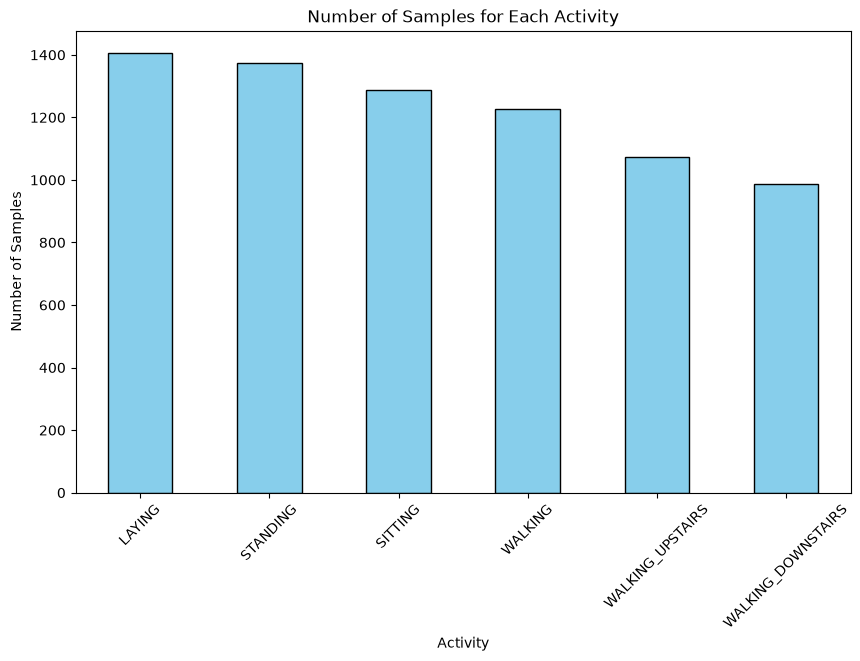

In [45]:
plt.figure(figsize=(10,6))

train_data["ActivityName"].value_counts().plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Number of Samples for Each Activity")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.show()

In [46]:
subject_count = train_data["Subject"].value_counts().sort_index()

subject_count

Subject
1     347
3     341
5     302
6     325
7     308
8     281
11    316
14    323
15    328
16    366
17    368
19    360
21    408
22    321
23    372
25    409
26    392
27    376
28    382
29    344
30    383
Name: count, dtype: int64

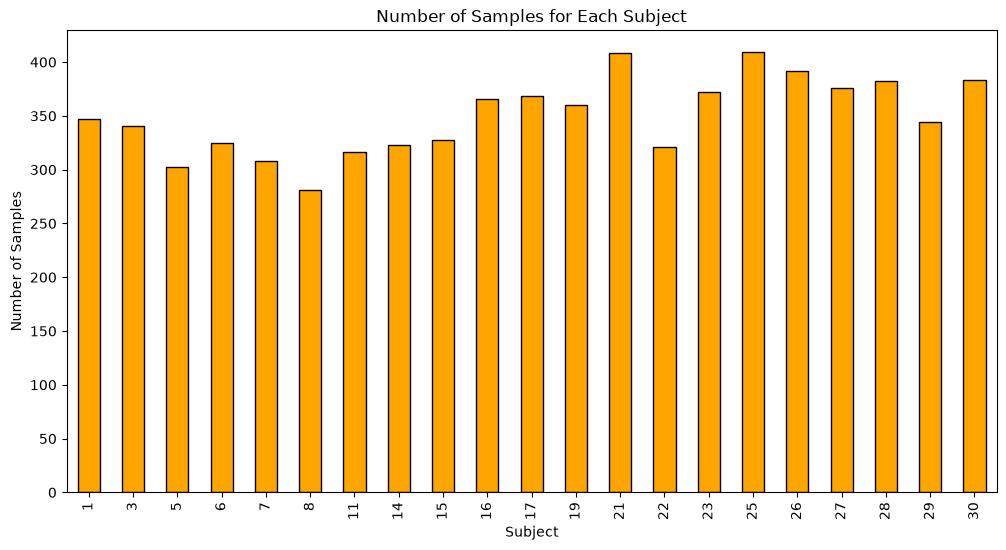

In [47]:
plt.figure(figsize=(12,6))

subject_count.plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Number of Samples for Each Subject")
plt.xlabel("Subject")
plt.ylabel("Number of Samples")

plt.show()

In [49]:
print(subject_count)

Subject
1     347
3     341
5     302
6     325
7     308
8     281
11    316
14    323
15    328
16    366
17    368
19    360
21    408
22    321
23    372
25    409
26    392
27    376
28    382
29    344
30    383
Name: count, dtype: int64


In [50]:
selected_features = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-mean()-Y",
    "tBodyAcc-mean()-Z",
    "tBodyAcc-std()-X",
    "tBodyAcc-std()-Y"
]

selected_features

['tBodyAcc-mean()-X',
 'tBodyAcc-mean()-Y',
 'tBodyAcc-mean()-Z',
 'tBodyAcc-std()-X',
 'tBodyAcc-std()-Y']

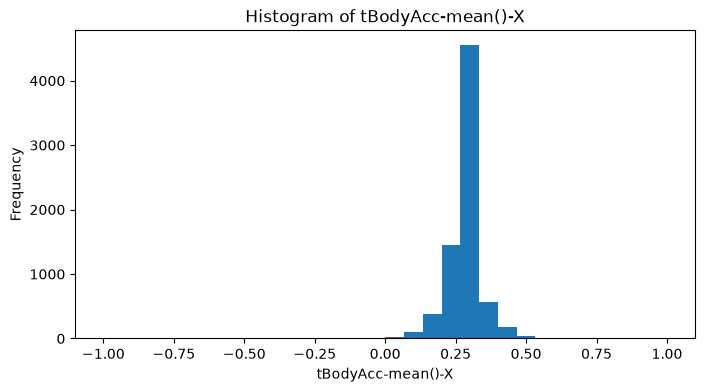

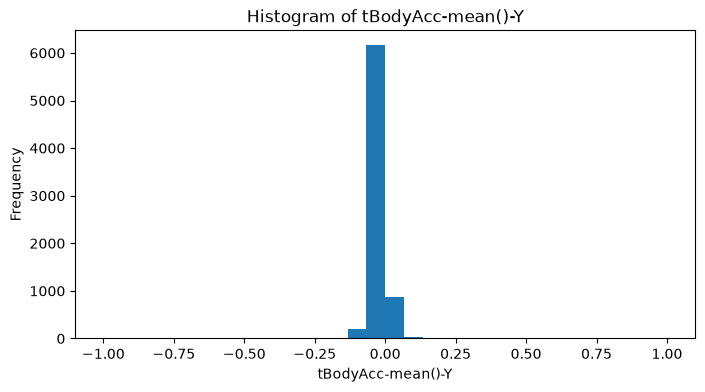

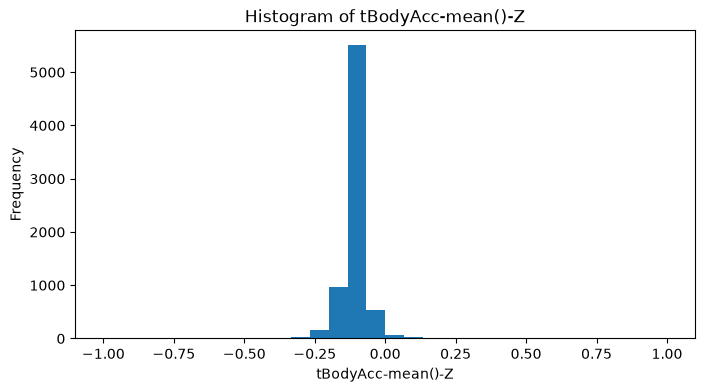

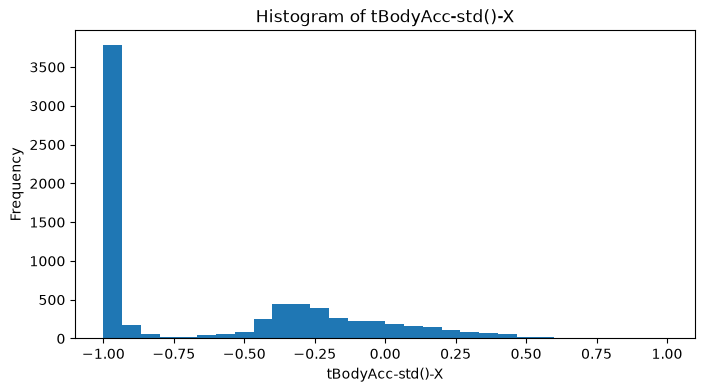

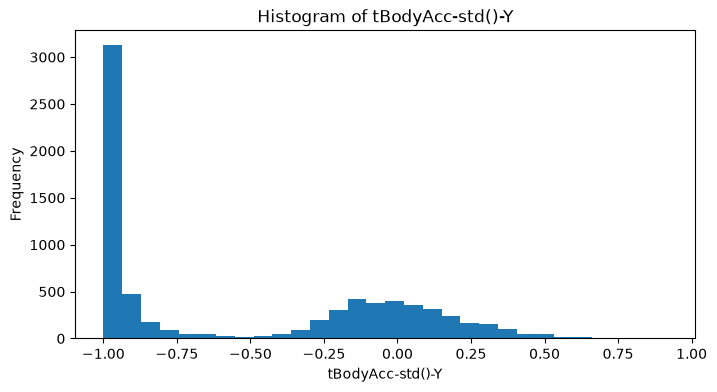

In [51]:
for feature in selected_features:
    plt.figure(figsize=(8,4))

    plt.hist(train_data[feature], bins=30)

    plt.title(f"Histogram of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.show()

### Nhận xét báo cáo
Phần lớn các đặc trưng đã được chuẩn hóa, giá trị chủ yếu nằm trong khoảng từ -1 đến 1. Phân bố của từng đặc trưng không hoàn toàn tuân theo phân phối chuẩn và có sự khác biệt giữa các hoạt động.

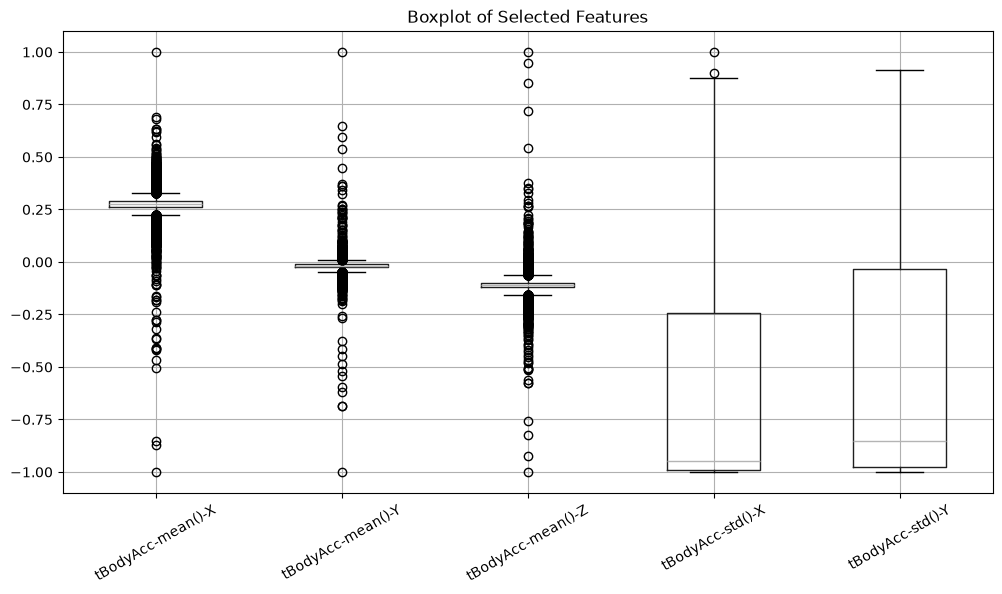

In [52]:
plt.figure(figsize=(12,6))

train_data[selected_features].boxplot()

plt.xticks(rotation=30)
plt.title("Boxplot of Selected Features")

plt.show()

#### Nhận xét báo cáo
Một số đặc trưng xuất hiện các điểm nằm ngoài khoảng tứ phân vị. Tuy nhiên, đây là đặc điểm bình thường của dữ liệu cảm biến và chưa cần loại bỏ trong giai đoạn EDA.

In [53]:
correlation = train_data.iloc[:, 2:12].corr()

correlation

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X
tBodyAcc-mean()-X,1.000000,0.148061,-0.256952,0.000619,-0.021903,-0.044617,0.006290,-0.022754,-0.047558,0.044062
tBodyAcc-mean()-Y,0.148061,1.000000,-0.078769,-0.045160,-0.044920,-0.049746,-0.044180,-0.045049,-0.050402,-0.038108
tBodyAcc-mean()-Z,-0.256952,-0.078769,1.000000,-0.020217,-0.016641,-0.008410,-0.018747,-0.015203,-0.001988,-0.037197
tBodyAcc-std()-X,0.000619,-0.045160,-0.020217,1.000000,0.927461,0.851668,0.998632,0.920888,0.846392,0.980844
tBodyAcc-std()-Y,-0.021903,-0.044920,-0.016641,0.927461,1.000000,0.895510,0.922803,0.997347,0.894509,0.917366
tBodyAcc-std()-Z,-0.044617,-0.049746,-0.008410,0.851668,0.895510,1.000000,0.844469,0.891441,0.997418,0.853884
tBodyAcc-mad()-X,0.006290,-0.044180,-0.018747,0.998632,0.922803,0.844469,1.000000,0.916106,0.839267,0.973216
tBodyAcc-mad()-Y,-0.022754,-0.045049,-0.015203,0.920888,0.997347,0.891441,0.916106,1.000000,0.891178,0.910411
tBodyAcc-mad()-Z,-0.047558,-0.050402,-0.001988,0.846392,0.894509,0.997418,0.839267,0.891178,1.000000,0.847870
tBodyAcc-max()-X,0.044062,-0.038108,-0.037197,0.980844,0.917366,0.853884,0.973216,0.910411,0.847870,1.000000


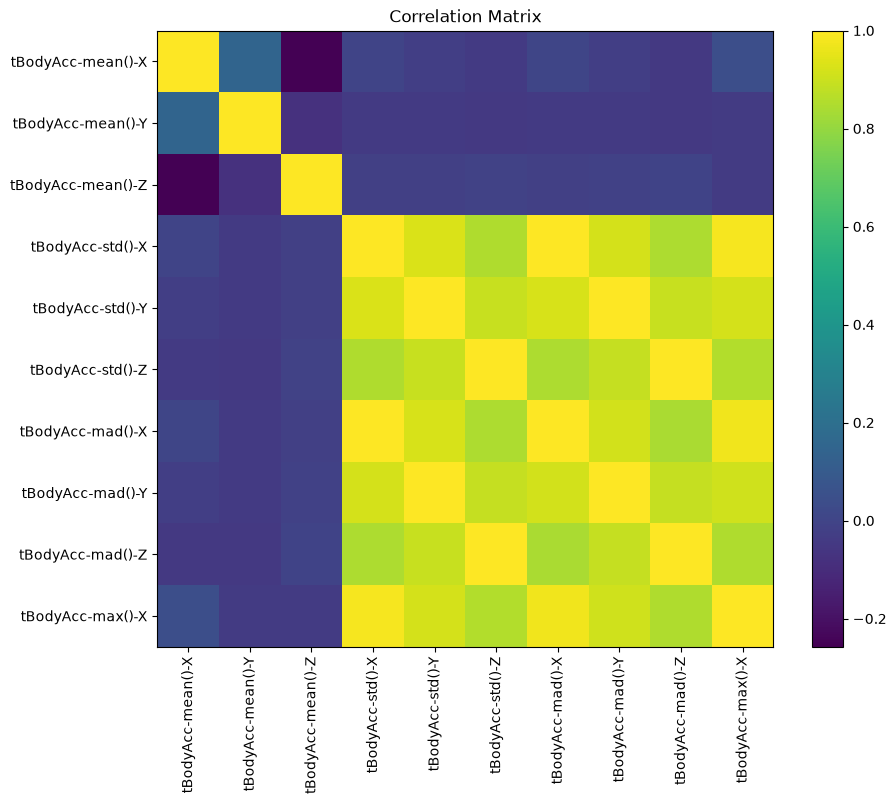

In [54]:
plt.figure(figsize=(10,8))

plt.imshow(correlation)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.show()

### Nhận xét báo cáo
Một số cặp đặc trưng có hệ số tương quan cao, phản ánh mối liên hệ giữa các phép đo từ cùng một cảm biến hoặc cùng một trục chuyển động.

In [56]:
activity_mean = train_data.groupby("ActivityName")[
    "tBodyAcc-mean()-X"
].mean()

activity_mean

ActivityName
LAYING                0.269191
SITTING               0.273449
STANDING              0.279294
WALKING               0.276260
WALKING_DOWNSTAIRS    0.288169
WALKING_UPSTAIRS      0.261930
Name: tBodyAcc-mean()-X, dtype: float64

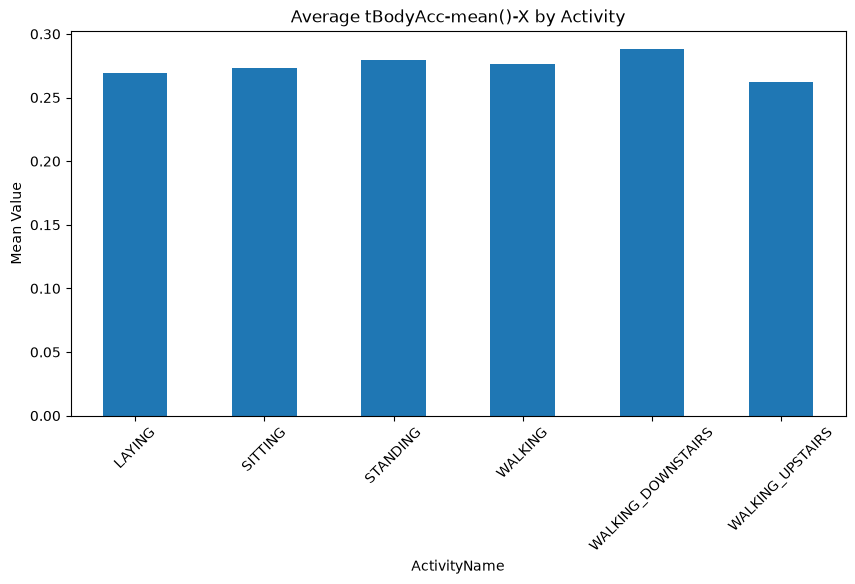

In [57]:
plt.figure(figsize=(10,5))

activity_mean.plot(kind="bar")

plt.title("Average tBodyAcc-mean()-X by Activity")
plt.ylabel("Mean Value")
plt.xticks(rotation=45)

plt.show()

### Ý nghĩa
Biểu đồ cho thấy giá trị trung bình của đặc trưng tBodyAcc-mean()-X ở từng hoạt động, giúp thấy sự khác biệt giữa các nhóm hoạt động.

### Bước 5  Tiền xử lý dữ liệu

In [63]:
X_test = pd.read_csv(
    DATA_PATH + "/test/X_test.txt",
    sep=r"\s+",
    header=None
)

X_test.columns = feature_names

print(X_test.shape)

(2947, 561)


In [65]:
y_test = pd.read_csv(
    DATA_PATH + "/test/y_test.txt",
    header=None,
    names=["Activity"]
)

print(y_test.shape)

(2947, 1)


In [66]:
subject_test = pd.read_csv(
    DATA_PATH + "/test/subject_test.txt",
    header=None,
    names=["Subject"]
)

print(subject_test.shape)

(2947, 1)


In [67]:
test_data = pd.concat(
    [subject_test, y_test, X_test],
    axis=1
)

test_data["ActivityName"] = test_data["Activity"].map(activity_dict)

print(test_data.shape)

(2947, 564)


In [68]:
all_data = pd.concat(
    [train_data, test_data],
    ignore_index=True
)

print(all_data.shape)

(10299, 564)


### Vì:
- Train: 7352
- Test: 2947

In [69]:
all_data.head()

,Subject,Activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",ActivityName
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


In [74]:
X = all_data.drop(
    columns=["Subject", "Activity", "ActivityName"]
)

y = all_data["Activity"]

print(X.shape)
print(y.shape)

(10299, 561)
(10299,)


In [71]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 10299 entries, 0 to 10298
Columns: 561 entries, tBodyAcc-mean()-X to angle(Z,gravityMean)
dtypes: float64(561)
memory usage: 44.1 MB


In [72]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [84]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X.to_numpy())

print(X_scaled.shape)

(10299, 561)


In [85]:
print("Shape:", X_scaled.shape)
print("Mean:", X_scaled.mean())
print("Std :", X_scaled.std())

Shape: (10299, 561)
Mean: 1.8009099792273252e-17
Std : 1.0


In [86]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(10299, 561)


In [87]:
explained_variance = pca.explained_variance_ratio_

print(explained_variance[:10])

[0.50738221 0.06239186 0.02692564 0.02452871 0.01888936 0.01631395
 0.01414533 0.01216211 0.00985248 0.00949228]


In [88]:
import numpy as np

cumulative_variance = np.cumsum(explained_variance)

print(cumulative_variance[:20])

[0.50738221 0.56977407 0.59669971 0.62122842 0.64011777 0.65643173
 0.67057706 0.68273917 0.69259164 0.70208392 0.71066696 0.71876676
 0.72642539 0.73319206 0.73949448 0.74565165 0.751605   0.75737696
 0.76301127 0.76841957]


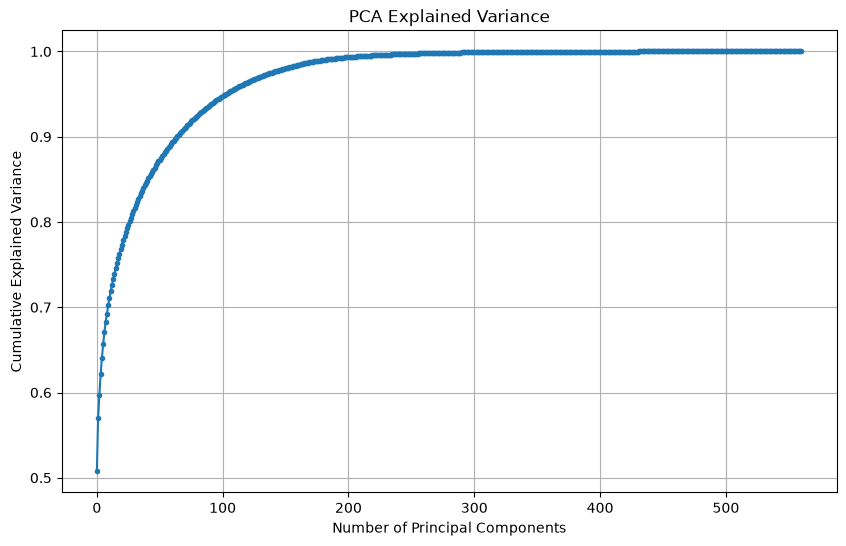

In [89]:
plt.figure(figsize=(10, 6))

plt.plot(cumulative_variance, marker="o", markersize=3)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid(True)

plt.show()

In [90]:
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Số thành phần PCA:", n_components)

Số thành phần PCA: 104


In [91]:
pca_final = PCA(
    n_components=n_components,
    random_state=42
)

X_pca_final = pca_final.fit_transform(X_scaled)

print(X_pca_final.shape)

(10299, 104)


In [92]:
pca_columns = [f"PC{i+1}" for i in range(X_pca_final.shape[1])]

X_pca_df = pd.DataFrame(
    X_pca_final,
    columns=pca_columns
)

X_pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC95,PC96,PC97,PC98,PC99,PC100,PC101,PC102,PC103,PC104
0,-16.380980,1.995083,3.415690,0.649858,-7.825062,-2.771964,-2.298285,-5.227723,1.335530,-3.760130,...,-0.453863,-0.952478,-0.643372,-2.644553,-1.672523,0.094326,-1.669191,0.045822,-2.044934,-1.053981
1,-15.582173,1.182594,-0.321207,-2.748083,-4.729536,-1.588823,0.334051,-1.621178,0.006349,0.072030,...,-0.617054,1.197205,0.157327,-0.182153,0.443352,-0.900287,-1.290595,-0.236736,0.302279,-0.503428
2,-15.423989,2.243166,-1.237784,-4.002881,-4.402735,-1.035089,0.129769,-1.279185,-0.190748,-0.780891,...,0.166897,-0.727894,0.067191,0.109415,0.018823,-1.166463,0.714439,0.637714,-0.284283,0.484183
3,-15.647807,3.762882,-1.275283,-2.806663,-3.239111,-0.743524,-0.326070,-1.742983,-0.912218,-1.594744,...,0.757726,-0.215954,0.237352,-1.008373,-0.043515,-0.563716,0.776140,-0.700228,-0.445514,0.241850
4,-15.842320,4.438897,-1.808232,-3.160507,-3.331172,-0.911551,0.861931,-0.090126,-0.521629,1.015852,...,-0.186292,0.278911,0.541911,-0.024492,-0.425371,0.207763,0.014403,-0.229281,0.432271,0.429974


### BƯỚC 6 - PHÂN CỤM K-MEANS

In [95]:
from sklearn.cluster import KMeans

In [97]:
sse = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_pca_final)

    sse.append(kmeans.inertia_)

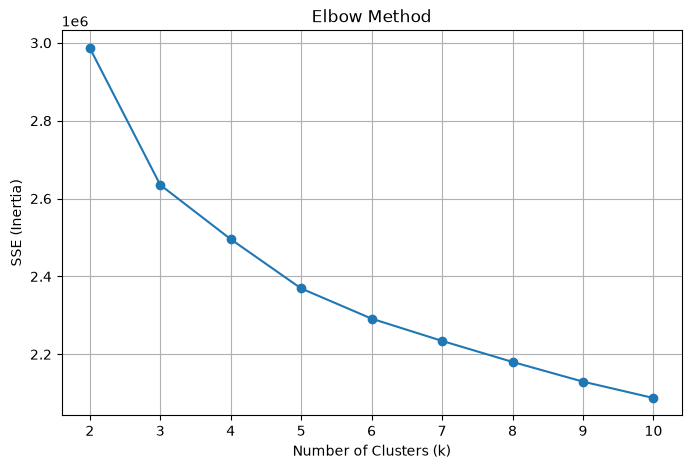

In [98]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), sse, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE (Inertia)")
plt.title("Elbow Method")

plt.grid(True)

plt.show()

In [99]:
k = 6

In [100]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_pca_final)

print(clusters[:20])

[3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 3 3 3 3 3]


In [101]:
cluster_counts = pd.Series(clusters).value_counts().sort_index()

print(cluster_counts)

0    1647
1    1349
2     307
3    2627
4    1921
5    2448
Name: count, dtype: int64


In [102]:
result_df = X_pca_df.copy()

result_df["Cluster"] = clusters

result_df["Activity"] = y.values

result_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC97,PC98,PC99,PC100,PC101,PC102,PC103,PC104,Cluster,Activity
0,-16.380980,1.995083,3.415690,0.649858,-7.825062,-2.771964,-2.298285,-5.227723,1.335530,-3.760130,...,-0.643372,-2.644553,-1.672523,0.094326,-1.669191,0.045822,-2.044934,-1.053981,3,5
1,-15.582173,1.182594,-0.321207,-2.748083,-4.729536,-1.588823,0.334051,-1.621178,0.006349,0.072030,...,0.157327,-0.182153,0.443352,-0.900287,-1.290595,-0.236736,0.302279,-0.503428,3,5
2,-15.423989,2.243166,-1.237784,-4.002881,-4.402735,-1.035089,0.129769,-1.279185,-0.190748,-0.780891,...,0.067191,0.109415,0.018823,-1.166463,0.714439,0.637714,-0.284283,0.484183,3,5
3,-15.647807,3.762882,-1.275283,-2.806663,-3.239111,-0.743524,-0.326070,-1.742983,-0.912218,-1.594744,...,0.237352,-1.008373,-0.043515,-0.563716,0.776140,-0.700228,-0.445514,0.241850,3,5
4,-15.842320,4.438897,-1.808232,-3.160507,-3.331172,-0.911551,0.861931,-0.090126,-0.521629,1.015852,...,0.541911,-0.024492,-0.425371,0.207763,0.014403,-0.229281,0.432271,0.429974,3,5


### BƯỚC 7 - ĐÁNH GIÁ KẾT QUẢ PHÂN CỤM

In [103]:
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

In [104]:
sil_score = silhouette_score(
    X_pca_final,
    clusters
)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.12227668311604448


In [105]:
ari = adjusted_rand_score(
    y,
    clusters
)

print("ARI:", ari)

ARI: 0.41931306944265484


In [106]:
nmi = normalized_mutual_info_score(
    y,
    clusters
)

print("NMI:", nmi)

NMI: 0.5592759978557332


In [107]:
evaluation = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Adjusted Rand Index",
        "Normalized Mutual Information"
    ],
    "Value": [
        sil_score,
        ari,
        nmi
    ]
})

evaluation

,Metric,Value
0,Silhouette Score,0.122277
1,Adjusted Rand Index,0.419313
2,Normalized Mutual Information,0.559276


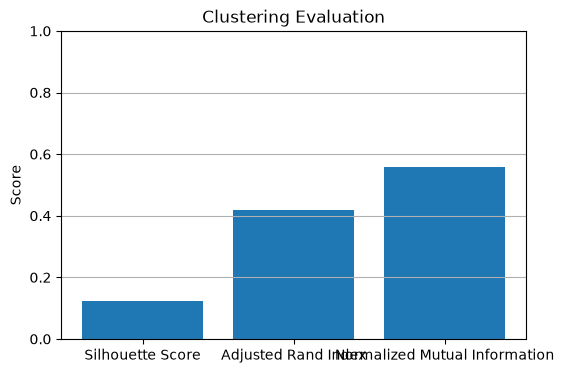

In [108]:
plt.figure(figsize=(6, 4))

plt.bar(
    evaluation["Metric"],
    evaluation["Value"]
)

plt.title("Clustering Evaluation")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.grid(axis="y")

plt.show()

### BƯỚC 8 - TRỰC QUAN HÓA KẾT QUẢ PHÂN CỤM

In [109]:
pca_2d = PCA(n_components=2, random_state=42)

X_pca_2d = pca_2d.fit_transform(X_scaled)

print(X_pca_2d.shape)

(10299, 2)


In [110]:
plot_df = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1],
    "Cluster": clusters,
    "Activity": y.values
})

plot_df.head()

,PC1,PC2,Cluster,Activity
0,-16.380980,1.995083,3,5
1,-15.582173,1.182594,3,5
2,-15.423989,2.243166,3,5
3,-15.647807,3.762882,3,5
4,-15.842320,4.438897,3,5


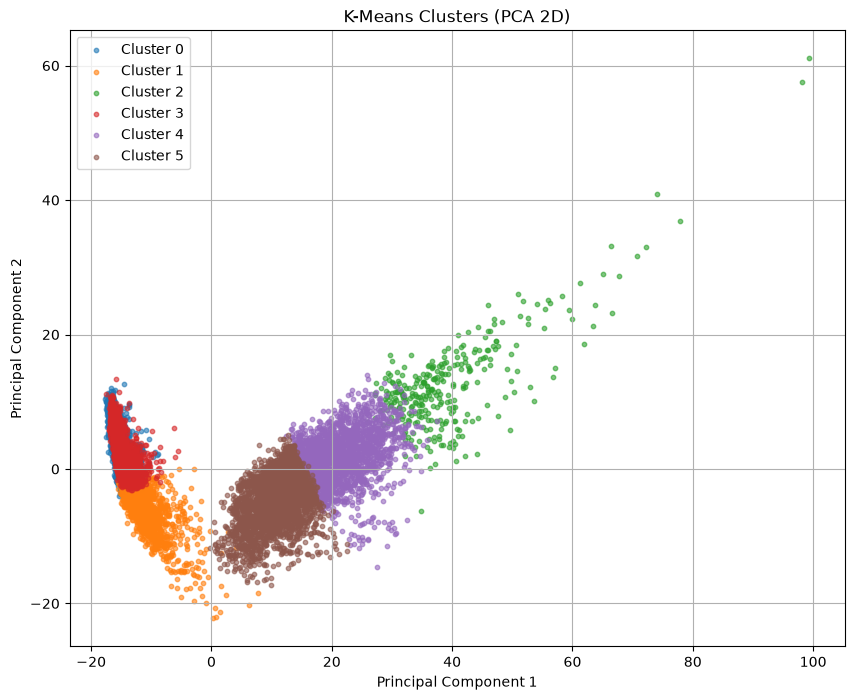

In [111]:
plt.figure(figsize=(10, 8))

for cluster in sorted(plot_df["Cluster"].unique()):
    subset = plot_df[plot_df["Cluster"] == cluster]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        s=10,
        alpha=0.6,
        label=f"Cluster {cluster}"
    )

plt.title("K-Means Clusters (PCA 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)

plt.show()

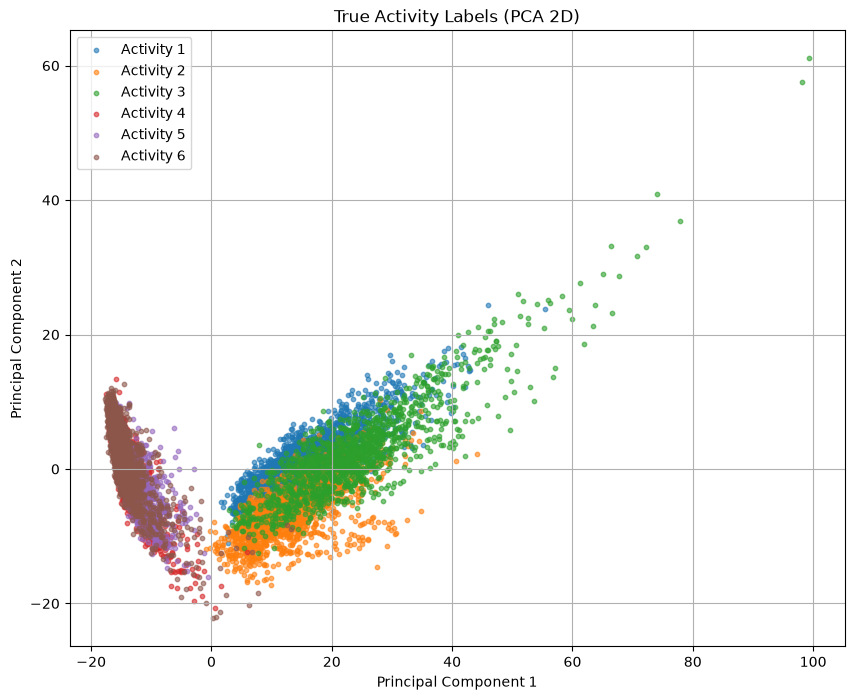

In [112]:
plt.figure(figsize=(10, 8))

for activity in sorted(plot_df["Activity"].unique()):
    subset = plot_df[plot_df["Activity"] == activity]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        s=10,
        alpha=0.6,
        label=f"Activity {activity}"
    )

plt.title("True Activity Labels (PCA 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)

plt.show()

In [113]:
plot_df.to_csv(
    "../results/kmeans_pca_results.csv",
    index=False
)

print("Đã lưu kết quả vào thư mục results.")

Đã lưu kết quả vào thư mục results.
